# Example 13.1: Surrogate Neural Network for Forward Kinematics
**Chapter 13 – Neural Networks for Four-Bar Linkage Mechanism Synthesis**

Train a 5→32→32→2 MLP to predict the coupler position (x_P, y_P).

In [1]:
from numpy import *
import matplotlib.pyplot as plt

random.seed(42)

def theta3(a, b, c, d, th2):
    x2 = a*cos(th2)-d; y2 = a*sin(th2)
    r  = sqrt(x2**2+y2**2)
    arg= clip((r**2+c**2-b**2)/(2*r*c), -1., 1.)
    return arctan2(y2, x2) + arccos(arg)

def acoplador_xy(a, b, c, d, th2, lp=40., delta=pi/6):
    t3 = theta3(a, b, c, d, th2)
    return a*cos(th2)+lp*cos(t3+delta), a*sin(th2)+lp*sin(t3+delta)

# Generate data
N=2000; X_list, Y_list = [], []
it=0
while len(X_list)<N and it<60000:
    it+=1
    a=random.uniform(20,80); b=random.uniform(40,120)
    c=random.uniform(40,120); d=85.
    s=sorted([a,b,c,d])
    if s[0]+s[3]>s[1]+s[2]: continue
    th2=random.uniform(0,2*pi)
    xP,yP=acoplador_xy(a,b,c,d,th2)
    if isnan(xP): continue
    X_list.append([a/120,b/120,c/120,d/120,th2/(2*pi)])
    Y_list.append([xP/200, yP/200])

X=array(X_list); Y=array(Y_list)
print(f"Samples generated: {len(X)}")

perm=random.permutation(len(X)); ntr=int(0.8*len(X))
Xtr,Ytr=X[perm[:ntr]],Y[perm[:ntr]]
Xv,Yv=X[perm[ntr:]],Y[perm[ntr:]]

def relu(z): return maximum(0,z)
W1=random.randn(5,32)*sqrt(2/5); b1=zeros((1,32))
W2=random.randn(32,32)*sqrt(2/32); b2=zeros((1,32))
W3=random.randn(32,2)*sqrt(2/32);  b3=zeros((1,2))
LR,BS,LAM=1e-3,64,1e-4
hist_tr, hist_val=[],[]

for ep in range(300):
    perm2=random.permutation(ntr)
    for s in range(0,ntr,BS):
        ib=perm2[s:s+BS]; xb,yb=Xtr[ib],Ytr[ib]
        Z1=xb@W1+b1; A1=relu(Z1); Z2=A1@W2+b2; A2=relu(Z2); yh=A2@W3+b3
        n=len(xb); dZ3=(yh-yb)/n
        dW3=A2.T@dZ3; db3=dZ3.sum(0,keepdims=True)
        dA2=dZ3@W3.T; dZ2=dA2*(Z2>0)
        dW2=A1.T@dZ2; db2=dZ2.sum(0,keepdims=True)
        dA1=dZ2@W2.T; dZ1=dA1*(Z1>0)
        dW1=xb.T@dZ1; db1g=dZ1.sum(0,keepdims=True)
        W1-=LR*(dW1+LAM*W1); b1-=LR*db1g
        W2-=LR*(dW2+LAM*W2); b2-=LR*db2
        W3-=LR*(dW3+LAM*W3); b3-=LR*db3
    def fwd(Xd):
        return relu(relu(Xd@W1+b1)@W2+b2)@W3+b3
    hist_tr.append(mean((fwd(Xtr)-Ytr)**2))
    hist_val.append(mean((fwd(Xv)-Yv)**2))
    if (ep+1)%50==0:
        print(f"Epoch {ep+1:3d}  MSE_tr={hist_tr[-1]:.5f}  MSE_val={hist_val[-1]:.5f}")

rmse=sqrt(hist_val[-1])
print(f"\nValidation RMSE (norm.): {rmse:.5f}")
print(f"Validation RMSE (mm):    {rmse*200:.2f} mm")



Samples generated: 2000
Epoch  50  MSE_tr=0.04491  MSE_val=0.04469
Epoch 100  MSE_tr=0.03643  MSE_val=0.03773
Epoch 150  MSE_tr=0.03301  MSE_val=0.03497
Epoch 200  MSE_tr=0.03078  MSE_val=0.03299
Epoch 250  MSE_tr=0.02902  MSE_val=0.03135
Epoch 300  MSE_tr=0.02757  MSE_val=0.02993

Validation RMSE (norm.): 0.17301
Validation RMSE (mm):    34.60 mm


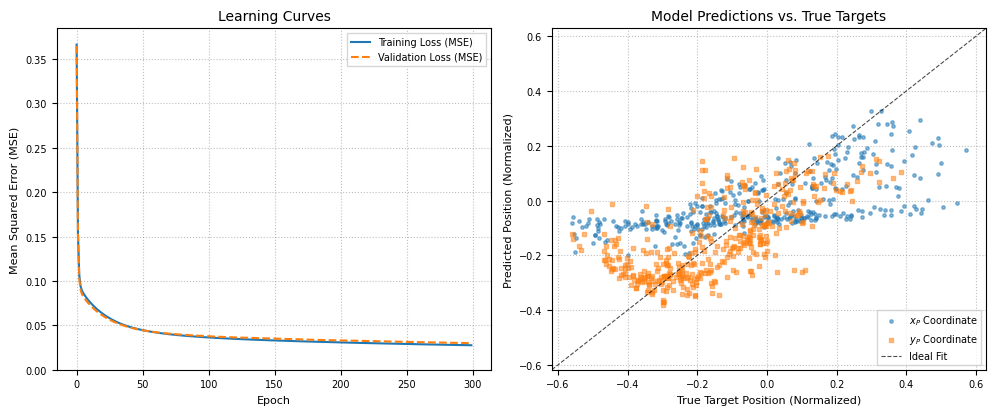

Figures successfully exported under publishing standards to:
 - ex13_1_surrogate_kinematics.pdf (Vector format)
 - ex13_1_surrogate_kinematics.png (600 DPI High-Resolution)


In [4]:
import os
import glob
import matplotlib.pyplot as plt
import numpy as np

# Dynamic naming system according to editorial standards
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "ex13_1_surrogate_kinematics"
except Exception:
    notebook_name = "ex13_1_surrogate_kinematics"

# Configure Springer publishing and vector-graphic parameters
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']
plt.rcParams['font.size'] = 8
plt.rcParams['axes.labelsize'] = 8
plt.rcParams['axes.titlesize'] = 10
plt.rcParams['legend.fontsize'] = 7
plt.rcParams['xtick.labelsize'] = 7
plt.rcParams['ytick.labelsize'] = 7

# Figure size optimized for double horizontal subplots (Springer column width)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

# Left Panel: Learning Curves
axes[0].plot(hist_tr, label='Training Loss (MSE)', color='#1f77b4', linewidth=1.5)
axes[0].plot(hist_val, label='Validation Loss (MSE)', color='#ff7f0e', linewidth=1.5, linestyle='--')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Mean Squared Error (MSE)')
axes[0].set_title('Learning Curves')
axes[0].legend(loc='upper right', frameon=True, fancybox=False, edgecolor='0.8')
axes[0].grid(True, linestyle=':', alpha=0.5, color='gray')

# Safe maximum extraction avoiding numpy namespace collisions with built-in max
max_tr = float(np.max(hist_tr))
max_val = float(np.max(hist_val))
overall_max = max_tr if max_tr > max_val else max_val
axes[0].set_ylim(bottom=0, top=overall_max * 1.05)

# Right Panel: Predicted vs. Real Coupler Position
Yhat = fwd(Xv)
axes[1].scatter(Yv[:, 0], Yhat[:, 0], alpha=0.5, s=6, label='$x_P$ Coordinate', color='#1f77b4', marker='o')
axes[1].scatter(Yv[:, 1], Yhat[:, 1], alpha=0.5, s=6, label='$y_P$ Coordinate', color='#ff7f0e', marker='s')

# Diagonal identity line
mn = float(np.minimum(Yv.min(), Yhat.min()))
mx = float(np.maximum(Yv.max(), Yhat.max()))
margin = (mx - mn) * 0.05
axes[1].plot([mn - margin, mx + margin], [mn - margin, mx + margin], 'k--', lw=0.8, alpha=0.7, label='Ideal Fit')

axes[1].set_xlabel('True Target Position (Normalized)')
axes[1].set_ylabel('Predicted Position (Normalized)')
axes[1].set_title('Model Predictions vs. True Targets')
axes[1].legend(loc='lower right', frameon=True, fancybox=False, edgecolor='0.8')
axes[1].grid(True, linestyle=':', alpha=0.5, color='gray')

# Set strict limit boundaries to prevent clipping of markers and layout cutoff
axes[1].set_xlim(mn - margin, mx + margin)
axes[1].set_ylim(mn - margin, mx + margin)

plt.tight_layout()

# Double Export under Springer requirements
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()

print(f"Figures successfully exported under publishing standards to:\n - {notebook_name}.pdf (Vector format)\n - {notebook_name}.png (600 DPI High-Resolution)")